# CIBERSORTx deconvolution 

Impute cell fractions from Srf oviduct bulk RNAseq data using reference cell types.

## Preliminary information

See https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE164291 for information about how the data were processed. See https://github.com/winuthayanon/estrus/blob/main/Estrus_Part1.ipynb for more information about the choices made in the below section.

## Export the single-cell matrix for CIBERSORTx

**This section was done in Python; please ensure your kernel is set correctly.**

Extract the single-cell expression matrix from Dr. Winuthayanon's data for use as the reference matrix in CIBERSORTx deconvolution.

In [24]:
import scanpy as sc
import pandas as pd
import numpy as np

In [25]:
# Read in the single-cell data.

st_path = "../offline/sc-rnaseq-GSE164291/Estrus_subset_analyzed.gzip.h5ad"
ad = sc.read_h5ad(st_path)
ad

AnnData object with n_obs × n_vars = 5073 × 17864
    obs: 'Clusters', '_X', '_Y', 'n_genes', 'percent_mito', 'n_counts', 'leiden', 'leiden_anno'
    var: 'Accession', 'Chromosome', 'End', 'Start', 'Strand', 'n_cells', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'mean', 'std'
    uns: "dendrogram_['leiden']", 'dendrogram_leiden', 'hvg', 'leiden', 'leiden_anno_colors', 'leiden_colors', 'neighbors', 'pca', 'rank_genes_groups', 'umap'
    obsm: 'X_pca', 'X_umap'
    varm: 'PCs'
    layers: 'ambiguous', 'matrix', 'spliced', 'unspliced'
    obsp: 'connectivities', 'distances'

/ddn/gs1/home/laispf/usr/local/miniforge3/envs/python/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


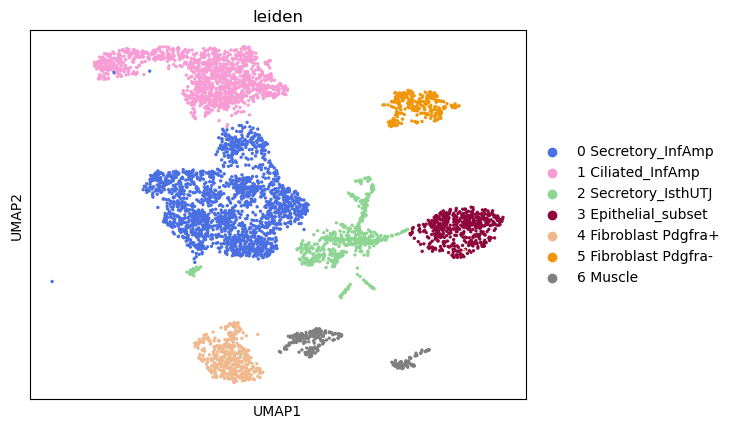

In [26]:
# Ensure our loaded file looks the same as the original scRNA-seq file
# Looks about the same from DataPreparationProcedure.ipynb.

sc.pl.umap(ad, color = "leiden")

In [27]:
# To compress our file, only write the highly variable genes to disk.
# We are writing standardized, normalized values.
# Flip the rows and columns to be compatible with CIBERSORTx.

hvf_matrix = ad.X[:,ad.var["highly_variable"]]
hvf_columns = ad.var.index[ad.var["highly_variable"]]
hvf_df = pd.DataFrame(hvf_matrix,
                      index = ad.obs["leiden"],
                      columns = hvf_columns).T
hvf_df.head()

leiden,2 Secretory_IsthUTJ,4 Fibroblast Pdgfra+,0 Secretory_InfAmp,1 Ciliated_InfAmp,1 Ciliated_InfAmp,0 Secretory_InfAmp,2 Secretory_IsthUTJ,4 Fibroblast Pdgfra+,0 Secretory_InfAmp,0 Secretory_InfAmp,...,0 Secretory_InfAmp,0 Secretory_InfAmp,0 Secretory_InfAmp,0 Secretory_InfAmp,4 Fibroblast Pdgfra+,0 Secretory_InfAmp,1 Ciliated_InfAmp,0 Secretory_InfAmp,5 Fibroblast Pdgfra-,0 Secretory_InfAmp
Mybl1,-0.049883,-0.156280,-0.123219,-0.121308,-0.094943,-0.120178,-0.083227,-0.068187,-0.091090,-0.111080,...,-0.091994,-0.114910,-0.101906,-0.158056,-0.076196,-0.102328,-0.119673,-0.100137,-0.075091,-0.126095
Vcpip1,-0.299736,-0.492444,-0.472726,3.590122,-0.416296,-0.468210,-0.359367,2.749283,-0.451654,-0.504257,...,-0.430689,-0.515637,1.180696,-0.520054,-0.391900,1.198178,-0.450175,-0.486979,-0.351314,-0.471607
Snhg6,-0.431572,-0.016651,-0.350852,-0.236476,-0.434465,-0.367779,-0.297640,-0.503528,-0.665881,0.592066,...,1.328603,-0.679500,-0.968788,-0.134403,-0.556426,-0.600930,-0.282247,-0.727400,-0.363533,-0.307299
Slco5a1,-0.072461,-0.041151,-0.153534,-0.093171,-0.148524,-0.156963,-0.060699,-0.138755,-0.257871,-0.293896,...,-0.199833,-0.304126,1.827159,-0.102978,-0.178471,-0.243998,-0.113353,-0.303616,-0.080178,-0.136515
Lactb2,-0.159905,-0.300429,-0.296038,-0.270204,-0.253592,-0.292991,-0.203199,-0.211503,-0.289903,-0.332338,...,-0.268994,-0.341742,-0.370211,-0.326629,-0.238178,-0.300703,-0.275583,-0.320372,-0.198989,-0.293648


In [29]:
# Load in the bulk data.

bulk_df_path = "../offline/sc-rnaseq-GSE164291/Counts-SRF-RawValues-NCBIRefSeq-TabSeparated.tsv"
bulk_df = pd.read_csv(bulk_df_path, sep="\t", index_col = 0)
bulk_df.head()

,results/aligned/processed/NS51478.Flox1_20240129_194256.L001.deduplicate.bam,results/aligned/processed/NS51478.Flox2_20240129_194256.L001.deduplicate.bam,results/aligned/processed/NS51478.Flox3_20240129_194256.L001.deduplicate.bam,results/aligned/processed/NS51478.Flox4_20240129_194256.L001.deduplicate.bam,results/aligned/processed/NS51478.Srfko1_20240129_194256.L001.deduplicate.bam,results/aligned/processed/NS51478.Srfko2_20240129_194256.L001.deduplicate.bam,results/aligned/processed/NS51478.Srfko3_20240129_194256.L001.deduplicate.bam,results/aligned/processed/NS51478.Srfko4_20240129_194256.L001.deduplicate.bam
TrnP,531,297,490,248,1046,667,550,460
CYTB,285672,126045,239264,87972,406537,323316,240628,204193
ND6,44256,22591,41514,16800,77474,52117,41620,36438
ND5,122325,63836,121834,43150,216536,148128,112433,97113
TrnL2,10,9,22,0,28,2,1,2


In [38]:
## Process the data exactly in the same way the Winuthayanon lab data was processed:
## 1. sc.pp.normalize_total procedure (see docs)
## 2. sc.pp.log1p procedure (see docs)
## 3. sc.pp.scale with max_value = 10 (see docs)

# 1. Each observation should have a total count equal to the median of total
#    counts for observations before normalization.

def normalize_total(arr, tgt):
    return arr / np.sum(arr) * tgt

def standardize(arr):
    return (arr - np.mean(arr)) / np.std(arr, ddof=1)

median = bulk_df.sum().median()
bulk_df_norm = bulk_df.apply(normalize_total, axis=0, args=(median,))

# 2. Logarithmize the data matrix with log1p.

bulk_df_1p = np.log1p(bulk_df_norm)
bulk_df_1p.head()

# 3. Scale all observations to unit variance and zero mean.
#    Unbiased estimator used for variance to match R conventions:
#    https://github.com/scverse/scanpy/blob/main/scanpy/preprocessing/_utils.py#L41

bulk_df_logscaled = bulk_df_1p.apply(standardize, axis=0).clip(lower=-10, upper=10)

bulk_df_logscaled.head()

,results/aligned/processed/NS51478.Flox1_20240129_194256.L001.deduplicate.bam,results/aligned/processed/NS51478.Flox2_20240129_194256.L001.deduplicate.bam,results/aligned/processed/NS51478.Flox3_20240129_194256.L001.deduplicate.bam,results/aligned/processed/NS51478.Flox4_20240129_194256.L001.deduplicate.bam,results/aligned/processed/NS51478.Srfko1_20240129_194256.L001.deduplicate.bam,results/aligned/processed/NS51478.Srfko2_20240129_194256.L001.deduplicate.bam,results/aligned/processed/NS51478.Srfko3_20240129_194256.L001.deduplicate.bam,results/aligned/processed/NS51478.Srfko4_20240129_194256.L001.deduplicate.bam
TrnP,0.158052,0.250934,0.188072,0.331498,0.284210,0.227413,0.293076,0.257320
CYTB,3.019259,3.045616,3.090148,2.953308,3.086405,2.998141,3.084897,3.022684
ND6,2.170366,2.251368,2.268818,2.213800,2.307133,2.180065,2.279109,2.240572
ND5,2.633168,2.731294,2.773668,2.635134,2.790290,2.648274,2.735474,2.685418
TrnL2,-1.596426,-1.337760,-1.246360,-2.543069,-1.389462,-2.135697,-2.298155,-2.043535


In [103]:
## Reverse the log scaling on both matrices.
## Super high outliers are messing up our analysis. Clip high values to 2 in log-space.

outlier_clipdist = 3

hvf_df_linspace_clipped = np.exp(hvf_df.clip(lower=-outlier_clipdist, upper=outlier_clipdist))
bulk_df_linspace_clipped = np.exp(bulk_df_logscaled.clip(lower=-outlier_clipdist, upper=outlier_clipdist))

In [104]:
hvf_df_linspace_clipped.head()

leiden,2 Secretory_IsthUTJ,4 Fibroblast Pdgfra+,0 Secretory_InfAmp,1 Ciliated_InfAmp,1 Ciliated_InfAmp,0 Secretory_InfAmp,2 Secretory_IsthUTJ,4 Fibroblast Pdgfra+,0 Secretory_InfAmp,0 Secretory_InfAmp,...,0 Secretory_InfAmp,0 Secretory_InfAmp,0 Secretory_InfAmp,0 Secretory_InfAmp,4 Fibroblast Pdgfra+,0 Secretory_InfAmp,1 Ciliated_InfAmp,0 Secretory_InfAmp,5 Fibroblast Pdgfra-,0 Secretory_InfAmp
Mybl1,0.951340,0.855320,0.884070,0.885761,0.909425,0.886762,0.920142,0.934086,0.912936,0.894867,...,0.912111,0.891446,0.903114,0.853802,0.926634,0.902734,0.887210,0.904714,0.927659,0.881531
Vcpip1,0.741014,0.611131,0.623301,20.085537,0.659485,0.626122,0.698118,15.631421,0.636574,0.603954,...,0.650061,0.597120,3.256638,0.594489,0.675772,3.314074,0.637516,0.614480,0.703763,0.623999
Snhg6,0.649487,0.983487,0.704088,0.789405,0.647611,0.692270,0.742569,0.604395,0.513821,1.807719,...,3.775764,0.506870,0.379543,0.874238,0.573254,0.548302,0.754087,0.483164,0.695216,0.735431
Slco5a1,0.930102,0.959684,0.857672,0.911038,0.861979,0.854736,0.941106,0.870441,0.772695,0.745354,...,0.818867,0.737768,6.216201,0.902147,0.836548,0.783489,0.892835,0.738144,0.922952,0.872393
Lactb2,0.852225,0.740500,0.743759,0.763224,0.776008,0.746029,0.816116,0.809367,0.748336,0.717245,...,0.764148,0.710532,0.690588,0.721351,0.788062,0.740298,0.759129,0.725879,0.819559,0.745539


In [105]:
bulk_df_linspace_clipped.head()

,results/aligned/processed/NS51478.Flox1_20240129_194256.L001.deduplicate.bam,results/aligned/processed/NS51478.Flox2_20240129_194256.L001.deduplicate.bam,results/aligned/processed/NS51478.Flox3_20240129_194256.L001.deduplicate.bam,results/aligned/processed/NS51478.Flox4_20240129_194256.L001.deduplicate.bam,results/aligned/processed/NS51478.Srfko1_20240129_194256.L001.deduplicate.bam,results/aligned/processed/NS51478.Srfko2_20240129_194256.L001.deduplicate.bam,results/aligned/processed/NS51478.Srfko3_20240129_194256.L001.deduplicate.bam,results/aligned/processed/NS51478.Srfko4_20240129_194256.L001.deduplicate.bam
TrnP,1.171227,1.285226,1.206920,1.393053,1.328711,1.255348,1.340545,1.293459
CYTB,20.085537,20.085537,20.085537,19.169255,20.085537,20.048227,20.085537,20.085537
ND6,8.761492,9.500726,9.667968,9.150421,10.045587,8.846882,9.767975,9.398704
ND5,13.917787,15.352740,16.017283,13.945183,16.285743,14.129629,15.417045,14.664337
TrnL2,0.202619,0.262433,0.287550,0.078625,0.249209,0.118162,0.100444,0.129570


In [106]:
## Overlap the two matrices.

intersection = np.array(set(hvf_df_linspace_clipped.index).intersection(set(bulk_df_linspace_clipped.index)))
hvf_df_linspace_clipped_isct = hvf_df_linspace_clipped.loc[intersection,:]
bulk_df_linspace_clipped_isct = bulk_df_linspace_clipped.loc[intersection,:]

([<matplotlib.axis.XTick at 0x7f506cada220>,
 [Text(1, 0, 'bulk_logspace_clip'), Text(2, 0, 'bulk_logspace_noclip')])

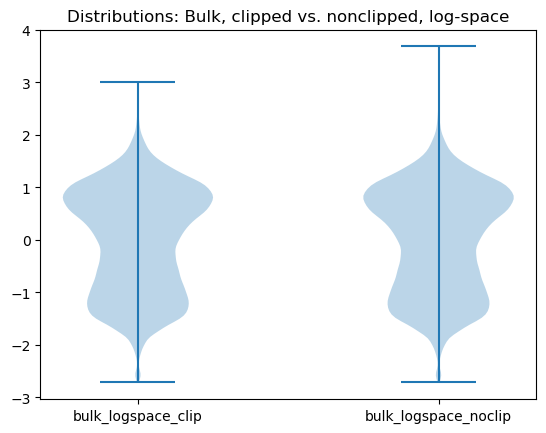

In [107]:
## Compare the distributions of normalized vs. non-normalized bulk data.

data_dict = {
    "bulk_logspace_clip": np.asarray(np.log(bulk_df_linspace_clipped)).flatten(),
    "bulk_logspace_noclip": np.asarray(bulk_df_logscaled).flatten()
} 

plt.title("Distributions: Bulk, clipped vs. nonclipped, log-space")
plt.violinplot(data_dict.values())
plt.xticks(np.arange(1,len(data_dict) + 1), data_dict.keys())

([<matplotlib.axis.XTick at 0x7f506ca41460>,
 [Text(1, 0, 'sc_logspace_clip'), Text(2, 0, 'sc_logspace_noclip')])

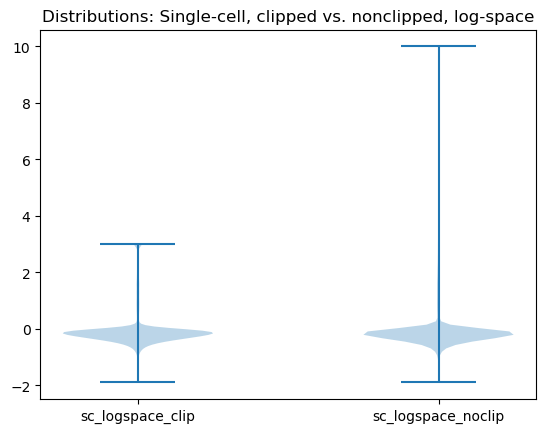

In [108]:
## Compare the distributions of normalized vs. non-normalized bulk data.

# Sampling because we have so many values!
data_dict = {
    "sc_logspace_clip": np.asarray(np.log(hvf_df_linspace_clipped)).flatten()[::1000],
    "sc_logspace_noclip": np.asarray(hvf_df).flatten()[::1000]
} 

plt.title("Distributions: Single-cell, clipped vs. nonclipped, log-space")
plt.violinplot(data_dict.values())
plt.xticks(np.arange(1,len(data_dict) + 1), data_dict.keys())

In [109]:
## Write intersected matrices to file.

hvf_df_linspace_clipped.to_csv("../offline/sc-rnaseq-GSE164291/Estrus_subset_analyzed-SCRefMat-HVFsOnly-NCBIRefSeq-AllGenes-Stdized+Clipped.tsv", sep="\t")
bulk_df_linspace_clipped.to_csv("../offline/sc-rnaseq-GSE164291/Counts-SRF-DESeq2Normed-NCBIRefSeq-AllGenes-Stdized+Clipped.tsv", sep="\t")
hvf_df_linspace_clipped_isct.to_csv("../offline/sc-rnaseq-GSE164291/Estrus_subset_analyzed_SCRefMat_HVFsOnly-NCBIRefSeq-CommonGenes-Stdized+Clipped.tsv", sep="\t")
bulk_df_linspace_clipped_isct.to_csv("../offline/sc-rnaseq-GSE164291/Counts-SRF-DESeq2Normed-NCBIRefSeq-CommonGenes-Stdized+Clipped.tsv", sep="\t")

## Run the deconvolution on Srf bulk RNAseq data using CIBERSORTx

The above reference data should be combined with a test single-cell matrix (e.g., single-cell data from Srf d/d samples) and uploaded to CIBERSORTx for processing. CIBERSORTx will then generate lists of reference cell fractions that are present in the test dats. Results from this process (which is done online and omitted here) are loaded and plotted below.

## Load, plot, and analyze the deconvoluted Srf bulk RNAseq data

**Done in R using ggplot2 and DESeq2. Please ensure your kernel is set correctly.**

In [3]:
library(ggplot2)
library(ggbeeswarm)
library(DESeq2)
library(data.table)
library(tidyverse)
library(stringr)

In [4]:
## load the deconvolution results.

res <- fread("../offline/sc-rnaseq-GSE164291/CIBERSORTxOutput/CIBERSORTx_Results.txt")
res$Mixture <- str_match(res$Mixture, "\\.(\\w+?)_")[,2]
res

Mixture,2 Secretory_IsthUTJ,4 Fibroblast Pdgfra+,0 Secretory_InfAmp,1 Ciliated_InfAmp,6 Muscle,5 Fibroblast Pdgfra-,3 Epithelial_subset,P-value,Correlation,RMSE
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Flox1,0.2379228,0.2592005,0.0001902573,0.04090237,0.3784753,0.08330878,0.000000000,0.00000000,0.14072216,1.015898
Flox2,0.2153996,0.2776132,0.0000000000,0.03224373,0.3788172,0.09592619,0.000000000,0.00000000,0.13995738,1.014271
Flox3,0.1976231,0.2645009,0.0015416154,0.04986399,0.3994201,0.08497663,0.002073631,0.00000000,0.14362851,1.011359
Flox4,0.2320142,0.2576230,0.0064737017,0.03871469,0.3510465,0.11412789,0.000000000,0.00000000,0.17094439,1.001898
Srfko1,0.2970137,0.4011939,0.0000000000,0.02480443,0.2019526,0.07503527,0.000000000,0.00501002,0.10229641,1.035902
Srfko2,0.4329220,0.3044203,0.0044070330,0.04233478,0.1271935,0.08872232,0.000000000,0.00000000,0.12221638,1.060378
Srfko3,0.4555995,0.3347078,0.0000000000,0.00000000,0.1960481,0.01364460,0.000000000,0.00000000,0.16582797,1.054430
Srfko4,0.5638559,0.2530369,0.0018658528,0.03601663,0.1215159,0.02370892,0.000000000,0.01202405,0.09122411,1.137276


In [5]:
## Plot the results, part 1.

# Convert to a ggplot-compatible dataframe.
curr_name <- ""
curr_list <- numeric(0)
res_df <- data.frame(sample=character(0), cluster=character(0), frac=numeric(0))

res_tmp <- res[,2:(ncol(res)-3)]
for (sample_name in res[['Mixture']]) {
    curr_vec <- unlist(res_tmp[res[['Mixture']] == sample_name,])
    curr_tmpdf <- data.frame(sample = sample_name,
                             cluster = names(curr_vec),
                             frac = as.vector(curr_vec))
    res_df <- rbind(res_df, curr_tmpdf)
}
res_df %>% group_by(sample) %>% slice_head()

sample,cluster,frac
<chr>,<chr>,<dbl>
Flox1,2 Secretory_IsthUTJ,0.2379228
Flox2,2 Secretory_IsthUTJ,0.2153996
Flox3,2 Secretory_IsthUTJ,0.1976231
Flox4,2 Secretory_IsthUTJ,0.2320142
Srfko1,2 Secretory_IsthUTJ,0.2970137
Srfko2,2 Secretory_IsthUTJ,0.4329220
Srfko3,2 Secretory_IsthUTJ,0.4555995
Srfko4,2 Secretory_IsthUTJ,0.5638559


In [7]:
## Plot the results, part 2.

# Make a grouped plot.
plt <- ggplot(res_df, aes(x = sample, y = frac, fill = cluster)) + 
              geom_col(color = 'white', position = 'stack') + 
              theme_light() +
              theme(axis.text.x = element_text(angle = 90))

pdf("032724-CIBERSORTxDeconvolution-GSE164291-SrfRNAseqBulk-NCBIRefSeq-BarChart-Wide.pdf",
    width=6, height=6)
plt
dev.off()

png 
  2

In [8]:
## Perform statistical analysis.

# Create a table suitable for use in t-testing.
res_stat_df <- res_df %>% mutate(group = sample,
                                 sample = NULL,
                                 cluster = as.factor(cluster))
res_stat_df$group <- as.factor(sapply(res_stat_df$group,
                                      function (x) { substring(x, 1, nchar(x)-1) }))

# Perform two-tailed t-tests between each group of cells. Report the cells with significant differences.
levels <- levels(res_stat_df$cluster)
pvals <- unlist(map(levels, function (level) { 
    t.test(frac ~ group, res_stat_df[res_stat_df$cluster == level,])$p.value 
}))
names(pvals) <- levels
sig_results <- sort(pvals[!is.na(pvals) & pvals < 0.05])
sig_results

6 Muscle 2 Secretory_IsthUTJ 
        0.000648045         0.027187678

png 
  2

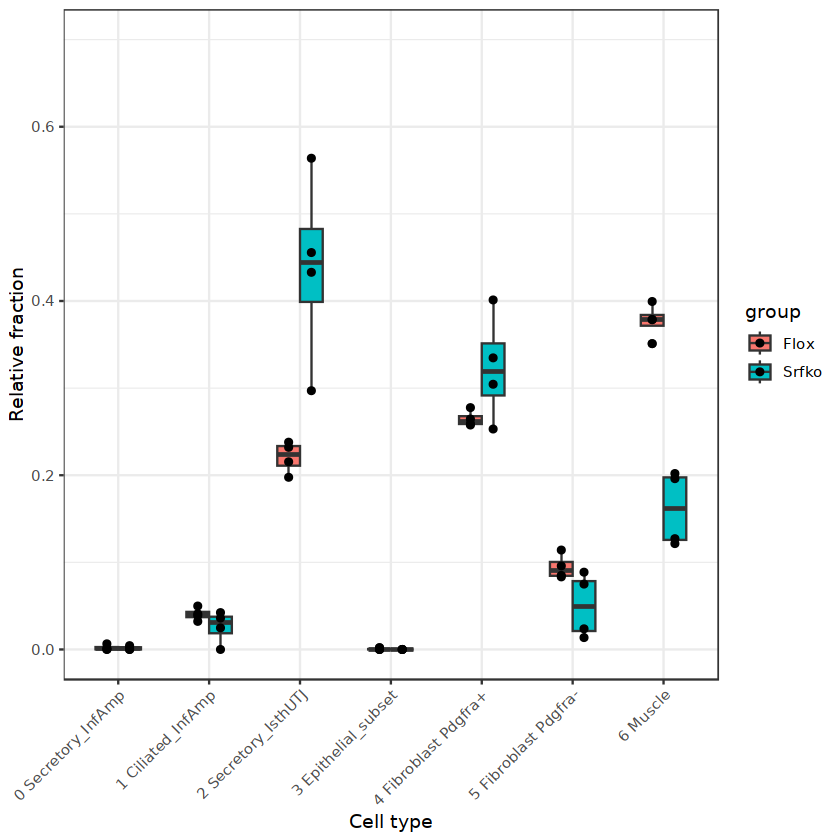

In [12]:
## Plot all results primitively.

plt <- ggplot(data = res_stat_df,
              aes(x = factor(cluster, level = levels), y = frac, fill = group)) +
    geom_boxplot(width = 0.5, position='dodge') + 
    geom_point(position = position_dodge(width = 0.5)) +
    xlab("Cell type") + 
    ylab("Relative fraction") + 
    theme_bw() + 
    expand_limits(y=0.7) +
    theme(axis.text.x = element_text(angle = 45, vjust = 1, hjust=1))
plt

pdf("032724-CIBERSORTxDeconvolution-GSE164291-SrfRNAseqBulk-NCBIRefSeq-AllDiffsChart-Wide.pdf",
    width=6, height=6)
plt
dev.off()

In [13]:
## Plot all results well: part 1.

# https://stackoverflow.com/questions/54672468/ggplot2-how-to-nudge-the-position-of-points-in-geom-beeswarm

#' Nudge any other positioning function from ggplot2
#' @param x Nudge in X direction
#' @param y Nudge in Y direction
#' @param position Any positioning operator from ggplot2 like \link{position_jitter}[ggplot2]
#' @return A combination positioning operator which first runs the original positioning,
#' then adds a nudge on top of that
#' @export
position_nudge_any <- function(x = 0, y = 0, position) {
  ggproto(NULL, PositionNudgeAny,
          nudge = ggplot2::position_nudge(x, y),
          position = position
  )
}


#' Internal class doing the actual nudging on top of the other operation
#' @keywords internal
PositionNudgeAny <- ggplot2::ggproto("PositionNudgeAny", ggplot2::Position,
  nudge = NULL,
  nudge_params = NULL,
  position = NULL,
  position_params = NULL,

  setup_params = function(self, data) {
   list(nudge = self$nudge,
        nudge_params = self$nudge$setup_params(data),
        position = self$position,
        position_params = self$position$setup_params(data))
  },

  setup_data = function(self, data, params) {
   data <- params$position$setup_data(data, params$position_params)
   params$nudge$setup_data(data, params$nudge_params)
  },

  compute_layer = function(self, data, params, layout) {
   data <- params$position$compute_layer(data, params$position_params, layout)
   params$nudge$compute_layer(data, params$nudge_params, layout)
  }
)



png 
  2

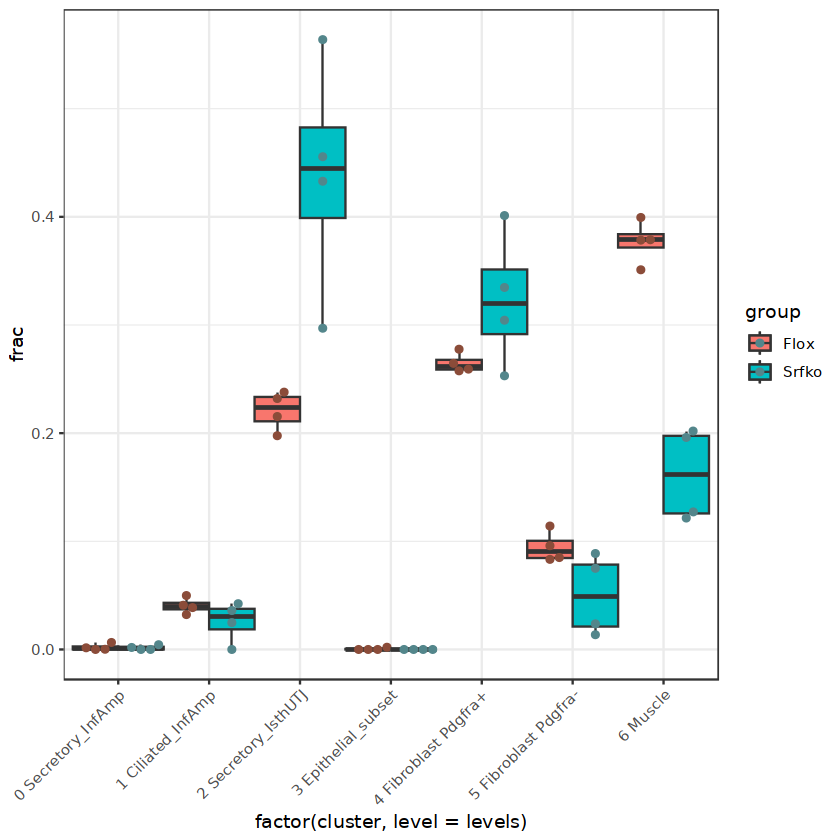

In [15]:
## Plot all results well: part 2.

plt <- ggplot(data = res_stat_df[res_stat_df$group == "Flox",],
              aes(x = factor(cluster, level = levels),
                  y = frac,
                  fill = group)) +
    geom_boxplot(width = 0.5,
                 position = position_nudge(x = -0.25, y = 0),
                 outlier.shape = NA) +
    geom_point(position=position_nudge_any(x=-0.25, y=0, ggbeeswarm::position_beeswarm(cex=1.5, side = 0, corral.width = 0.4)), color = "salmon4") +
    geom_boxplot(data = res_stat_df[res_stat_df$group == "Srfko",],
                 width = 0.5,
                 position = position_nudge(x = 0.25, y = 0)) +
    geom_point(data = res_stat_df[res_stat_df$group == "Srfko",],
               position=position_nudge_any(x=0.25, y=0, ggbeeswarm::position_beeswarm(cex=1.5, side = 0, corral.width = 0.4)), color = "cadetblue4") +
    theme_bw() +
    theme(axis.text.x = element_text(angle = 45, hjust = 1))
plt

pdf("032724-CIBERSORTxDeconvolution-GSE164291-SrfRNAseqBulk-NCBIRefSeq-AllDiffsChart-Wide.pdf",
    width=6, height=6)
plt
dev.off()

In [ ]:
## Plot all results.

plt <- ggplot(data = res_stat_df,
              aes(x = factor(cluster, level = levels), y = frac, fill = group)) +
    geom_boxplot(width = 0.5, position='dodge') + 
    geom_point(position = position_dodge(width = 0.5)) +
    xlab("Cell type") + 
    ylab("Relative fraction") + 
    theme_bw() + 
    expand_limits(y=0.7) +
    theme(axis.text.x = element_text(angle = 45, vjust = 1, hjust=1))
plt

pdf("032724-CIBERSORTxDeconvolution-GSE164291-SrfRNAseqBulk-NCBIRefSeq-AllDiffsChart.pdf",
    width=6, height=4)
plt
dev.off()

png 
  2

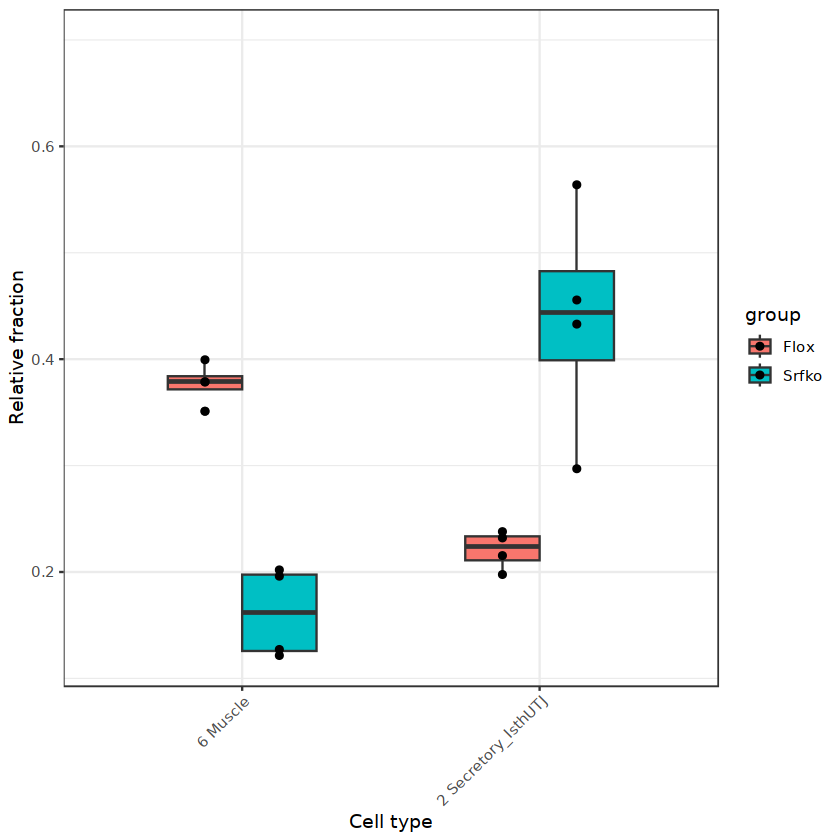

In [69]:
## Plot the significantly changed results.

plt <- ggplot(data = res_stat_df[res_stat_df$cluster %in% names(sig_results),],
              aes(x = factor(cluster, level = names(sig_results)), y = frac, fill = group)) +
    geom_boxplot(width = 0.5, position='dodge') + 
    geom_point(position = position_dodge(width = 0.5)) +
    xlab("Cell type") + 
    ylab("Relative fraction") + 
    theme_bw() + 
    expand_limits(y=0.7) +
    theme(axis.text.x = element_text(angle = 45, vjust = 1, hjust=1))
plt

pdf("032724-CIBERSORTxDeconvolution-GSE164291-SrfRNAseqBulk-NCBIRefSeq-SignificantDiffsChart.pdf",
    width=6, height=4)
plt
dev.off()

**Interpretation:** there is an expected decrease in the estimated fraction of muscle cells and an increase in the fraction of secretory epithelial cells. Note that the bulk samples contained cells from all regions of the oviduct; the representative cell types come from the regions listed on the classes on the x-axis.

It seems that there is a decrease in muscular activity in the oviduct and also a change in secretory phenotype. More investigation is warranted into secretory genes within the oviduct.